# ROHs and Their Association with HIV Resistance


## Methods

1. Import affymetrix 500k genechip files.
2. Find all ROHs with a minimum of 500kb and at least 2 SNPs.
3. Stratify data by chromosome.
4. For each chromosome, count number of ROHs per patient and test number of ROHs for association with HIV resistance.
5. For each chromosome, sum all lengths of ROHs per patient and test sum of lengths for association with HIV resistance.
6. For each chromosome, cluster homozygous SNPs based on regions of occurrence and test if clustered homozygous SNP genotypes in HIV resistant patients are associated with HIV resistance when comparing with the same regions of susceptible patients. 

In [1]:
import csv
from collections import defaultdict

import itables.options as opt
import pandas as pd
import scipy.stats as stats
import seaborn as sns
from IPython.display import JSON, Markdown
from itables import init_notebook_mode
from matplotlib import pyplot as plt
from scipy import sparse
from tqdm import tqdm

opt.maxBytes = 1048576
init_notebook_mode(all_interactive=True)

<IPython.core.display.Javascript object>

### Loading Data

In [2]:
rohs_df = pd.read_csv("Data/ROHs.csv", dtype={
    "Chromosome Name": str
})
rohs_df["strict_resistance"].replace(
    {
        "resistant": "resistant",
        "positive": "susceptible",
        "late converter": "susceptible",
    },
    inplace=True,
)
chromosome_order = [*[str(chr) for chr in range(1, 23)], "X"]
display(rohs_df)

CHP_File Chromosome Name  Start Position  End Position  Length (bp)  \
0       ML0002               1       108547196     110106932      1559736   
1       ML0002               1       120323283     143887291     23564008   
2       ML0002               1       145818022     148262976      2444954   
3       ML0002               1       159046119     160371387      1325268   
4       ML0005               1        12606008      13647613      1041605   
...        ...             ...             ...           ...          ...   
22779   ML2287               X        51666564      53272016      1605452   
22780   ML2287               X        62649321      64744198      2094877   
22781   ML2287               X        89185625      90281957      1096332   
22782   ML2287               X       126420505     127533795      1113290   
22783   ML2287               X       153233870     154569169      1335299   

       Start Index  End Index      Start SNP        End SNP  # SNPs  ...  \
0            16994      17138  SNP_A-2302781  SNP_A-1888860     145  ...   
1            18986      19006  SNP_A-2185978  SNP_A-1880667      21  ...   
2            19192      19231  SNP_A-1902033  SNP_A-2271305      40  ...   
3            20729      20938  SNP_A-1781453  SNP_A-2310217     210  ...   
4             2235       2263  SNP_A-2160424  SNP_A-1798804      29  ...   
...            ...        ...            ...            ...     ...  ...   
22779       435029     435048  SNP_A-4288337  SNP_A-2069471      20  ...   
22780       435225     435254  SNP_A-4295402  SNP_A-2203165      30  ...   
22781       436482     436511  SNP_A-1820773  SNP_A-2062911      30  ...   
22782       438778     438833  SNP_A-2050216  SNP_A-2217524      56  ...   
22783       440797     440832  SNP_A-4288301  SNP_A-2283915      36  ...   

                  home1      HOME  year_of_birth      Tribes_birth  \
0              Tanzania  Tanzania           1960  Tanzania, Bantus   
1              Tanzania  Tanzania           1960  Tanzania, Bantus   
2              Tanzania  Tanzania           1960  Tanzania, Bantus   
3              Tanzania  Tanzania           1960  Tanzania, Bantus   
4      Bukoba, Tanzania  Tanzania           1961  Tanzania, Bantus   
...                 ...       ...            ...               ...   
22779   MURANG'A, Kenya     Kenya              ?     Bantus, Kenya   
22780   MURANG'A, Kenya     Kenya              ?     Bantus, Kenya   
22781   MURANG'A, Kenya     Kenya              ?     Bantus, Kenya   
22782   MURANG'A, Kenya     Kenya              ?     Bantus, Kenya   
22783   MURANG'A, Kenya     Kenya              ?     Bantus, Kenya   

        Tribes_language        bantus_nilotes                tribes_Language2  \
0      Bantus, Tanzania  Bantus, all included  Bantus, Tanzania, Uganda, etc.   
1      Bantus, Tanzania  Bantus, all included  Bantus, Tanzania, Uganda, etc.   
2      Bantus, Tanzania  Bantus, all included  Bantus, Tanzania, Uganda, etc.   
3      Bantus, Tanzania  Bantus, all included  Bantus, Tanzania, Uganda, etc.   
4      Bantus, Tanzania  Bantus, all included  Bantus, Tanzania, Uganda, etc.   
...                 ...                   ...                             ...   
22779     Bantus, Kenya  Bantus, all included                   Bantus, Kenya   
22780     Bantus, Kenya  Bantus, all included                   Bantus, Kenya   
22781     Bantus, Kenya  Bantus, all included                   Bantus, Kenya   
22782     Bantus, Kenya  Bantus, all included                   Bantus, Kenya   
22783     Bantus, Kenya  Bantus, all included                   Bantus, Kenya   

                    tribes_Language3               tribes_Language4  \
0      Bantus, Tanzania, Uganda, etc  Bantus, Tanzania, Uganda, etc   
1      Bantus, Tanzania, Uganda, etc  Bantus, Tanzania, Uganda, etc   
2      Bantus, Tanzania, Uganda, etc  Bantus, Tanzania, Uganda, etc   
3      Bantus, Tanzania, Uganda, etc  Bantus, Tanzania, Uganda, etc   

### Organize Patients by HIV Resistance

<Axes: ylabel='Resistance Counts'>

strict_resistance  count
0       susceptible    394
1         resistant    116

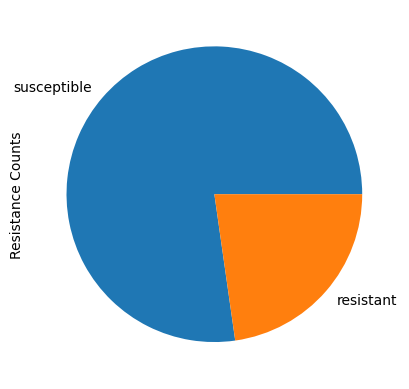

In [3]:
hiv_resistance_proportions = (
    rohs_df.groupby("CHP_File").last().value_counts("strict_resistance")
)

display(hiv_resistance_proportions.plot.pie(ylabel="Resistance Counts"))
display(hiv_resistance_proportions.reset_index())

### Counting Number of ROHs per Patient

In [4]:
roh_count_per_patient = (
    rohs_df.value_counts(["Chromosome Name", "strict_resistance", "CHP_File"])
    .to_frame()
    .reset_index()
)

display(roh_count_per_patient)

Chromosome Name strict_resistance CHP_File  count
0                   6       susceptible   ML1044     14
1                   X         resistant   ML1608     13
2                   X       susceptible   ML0412     13
3                   X       susceptible   ML1151     13
4                   X         resistant   ML1860     12
...               ...               ...      ...    ...
10112              15       susceptible   ML2072      1
10113               5         resistant   ML1749      1
10114              20       susceptible   ML1569      1
10115              15       susceptible   ML2052      1
10116              19       susceptible   ML1778      1

[10117 rows x 4 columns]

### T-Test on Number of ROHs and Resistance

Chromosome   P-Value  T-Statistic
0           1  0.964463    -0.044617
1          10  0.025517    -2.250192
2          11  0.274042     1.097852
3          12  0.799695     0.254152
4          13  0.272067     1.113018
5          14  0.127200    -1.534561
6          15  0.792432    -0.263601
7          16  0.948092     0.065182
8          17  0.833941    -0.210466
9          18  0.317259    -1.002251
10         19  0.503188    -0.670816
11          2  0.779019    -0.281038
12         20  0.072644    -1.802544
13         21  0.591069     0.538671
14         22  0.327779    -0.985931
15          3  0.189532    -1.316804
16          4  0.876055    -0.156188
17          5  0.770148     0.292650
18          6  0.452126     0.753794
19          7  0.717871    -0.361824
20          8  0.421961     0.805104
21          9  0.771883     0.290396
22          X  0.284034     1.074171

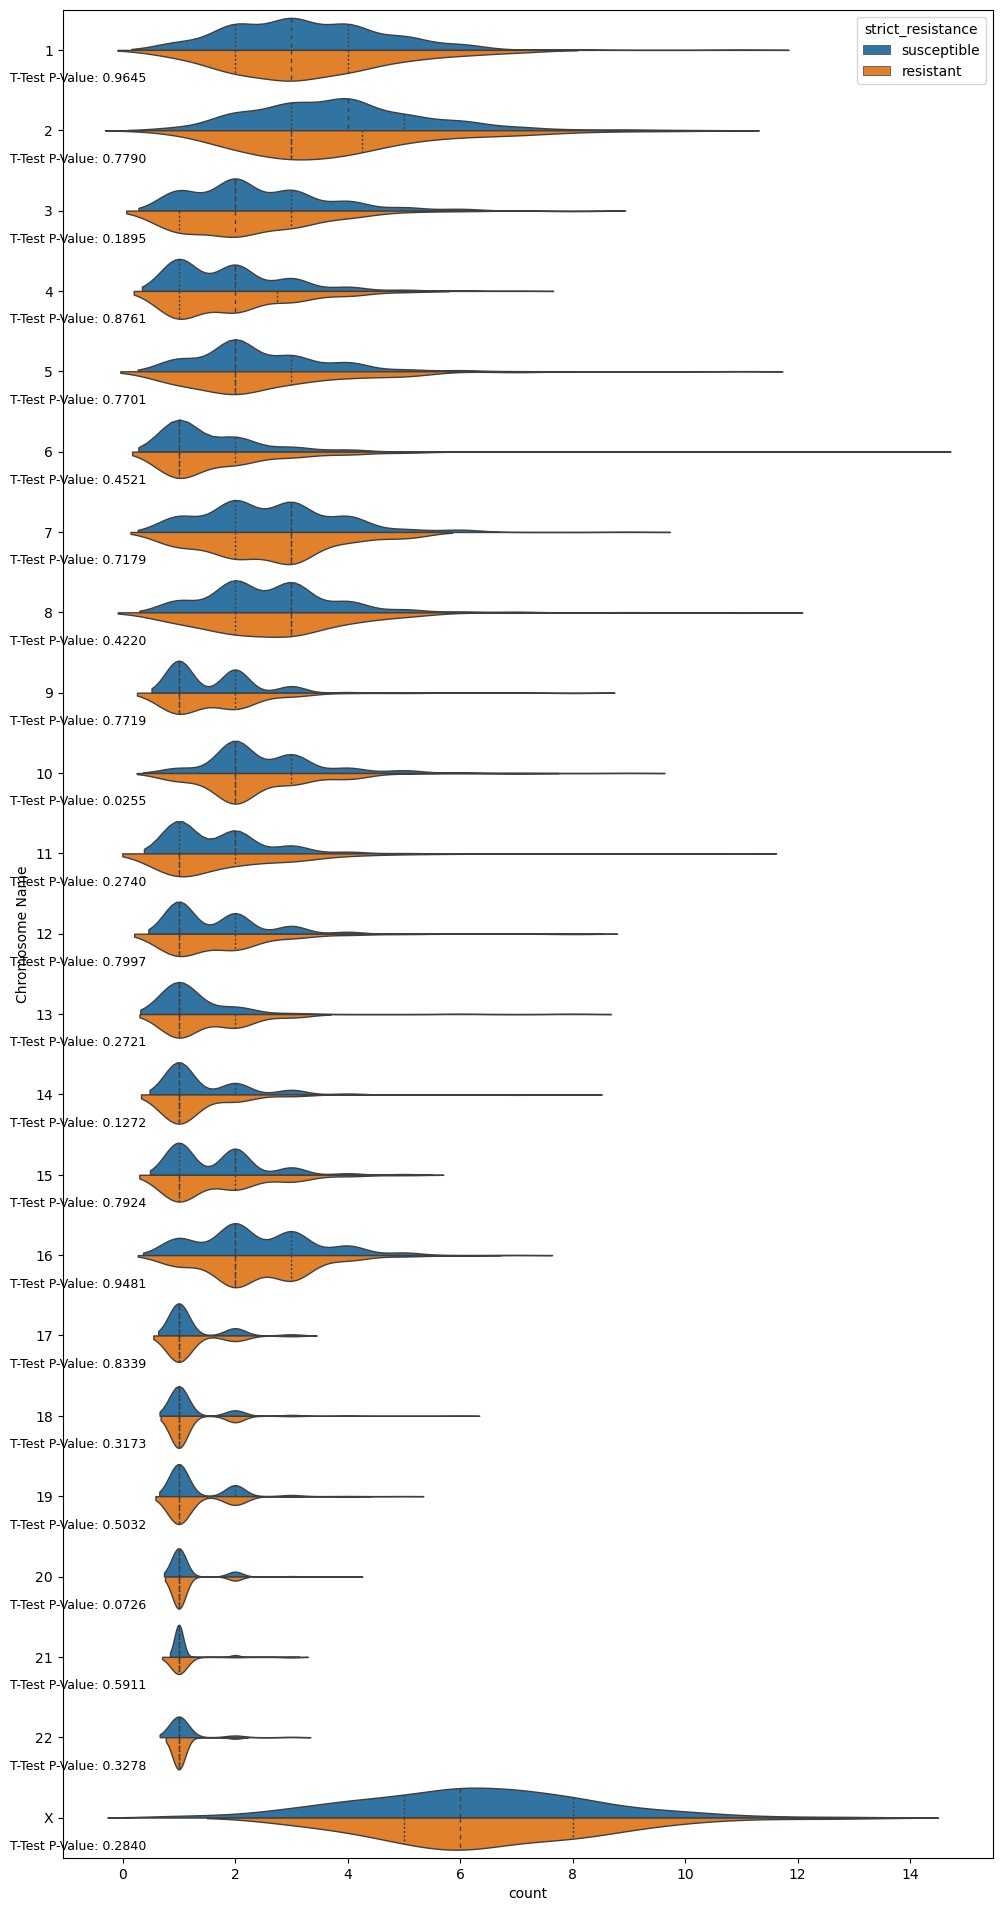

In [5]:
roh_count_resistance_association_results = {
    "Chromosome": [],
    "P-Value": [],
    "T-Statistic": [],
}

for chromosome, roh_counts in roh_count_per_patient.groupby("Chromosome Name"):
    resistant_group = list(
        roh_counts[roh_counts["strict_resistance"] == "resistant"]["count"]
    )
    susceptible_group = list(
        roh_counts[roh_counts["strict_resistance"] != "resistant"]["count"]
    )
    tstat, pval = stats.ttest_ind(resistant_group, susceptible_group, equal_var=False)
    roh_count_resistance_association_results["Chromosome"].append(chromosome)
    roh_count_resistance_association_results["P-Value"].append(pval)
    roh_count_resistance_association_results["T-Statistic"].append(tstat)

    plt.figure(figsize=(9, 6))
    axs = sns.violinplot(
        data=roh_counts,
        x="count",
        y="strict_resistance",
        width=0.45,
        inner="quartile",
    )
    axs.text(
        0.7, 0.9, f"T-Test P-Val: {pval:.4E}", fontsize=10, transform=axs.transAxes
    )
    sns.stripplot(
        data=roh_counts,
        x="count",
        y="strict_resistance",
        color="k",
        alpha=0.5,
        jitter=True,
    )
    plt.savefig(
        f"ROH Count Association with Resistance/Chromosome {chromosome} T-Test.svg",
        format="svg",
    )
    plt.close()

roh_count_resistance_association_results = pd.DataFrame(
    roh_count_resistance_association_results
)

display(roh_count_resistance_association_results)

plt.figure(figsize=(12, 24))
ax = sns.violinplot(
    data=roh_count_per_patient,
    x="count",
    y="Chromosome Name",
    hue="strict_resistance",
    order=chromosome_order,
    inner="quartile",
    split=True,
    linewidth=1,
)

for index, row in roh_count_resistance_association_results[
    ["Chromosome", "P-Value"]
].iterrows():
    chrom = row["Chromosome"]
    pval = row["P-Value"]
    ax.text(
        -2,
        chromosome_order.index(chrom) + 0.4,
        f"T-Test P-Value: {pval:.4f}",
        fontsize=9,
    )

plt.savefig(
    f"ROH Count Association with Resistance/Summary Chromosome T-Test.svg",
    format="svg",
)

### Sum of ROH Lengths per Patient

In [6]:
roh_total_length_per_patient = (
    rohs_df.groupby(["Chromosome Name", "CHP_File", "strict_resistance"])["Length (bp)"]
    .sum()
    .reset_index()
)
display(roh_total_length_per_patient)

Chromosome Name CHP_File strict_resistance  Length (bp)
0                   1   ML0002       susceptible     28893966
1                   1   ML0005       susceptible     27499327
2                   1   ML0013       susceptible     26250063
3                   1   ML0016       susceptible      2215385
4                   1   ML0024       susceptible     26797043
...               ...      ...               ...          ...
10112               X   ML2272       susceptible     20761082
10113               X   ML2278       susceptible     14533877
10114               X   ML2280       susceptible     10439398
10115               X   ML2285       susceptible      9461921
10116               X   ML2287       susceptible      7245250

[10117 rows x 4 columns]

### T-Test on Total ROH Lengths and Resistance

Chromosome   P-Value  T-Statistic
0           1  0.529617     0.629758
1          10  0.069968    -1.822925
2          11  0.374225     0.890916
3          12  0.247008     1.162251
4          13  0.439206     0.778764
5          14  0.260830    -1.128962
6          15  0.677106    -0.417126
7          16  0.097214     1.665050
8          17  0.282311    -1.082740
9          18  0.326133    -0.983458
10         19  0.457521    -0.744265
11          2  0.741469     0.330455
12         20  0.021446    -2.319785
13         21  0.333342     0.970717
14         22  0.367971    -0.906393
15          3  0.787703    -0.269709
16          4  0.171381     1.373220
17          5  0.954357     0.057316
18          6  0.917877     0.103256
19          7  0.714146    -0.366878
20          8  0.785506     0.272578
21          9  0.883652     0.146560
22          X  0.543793     0.608527

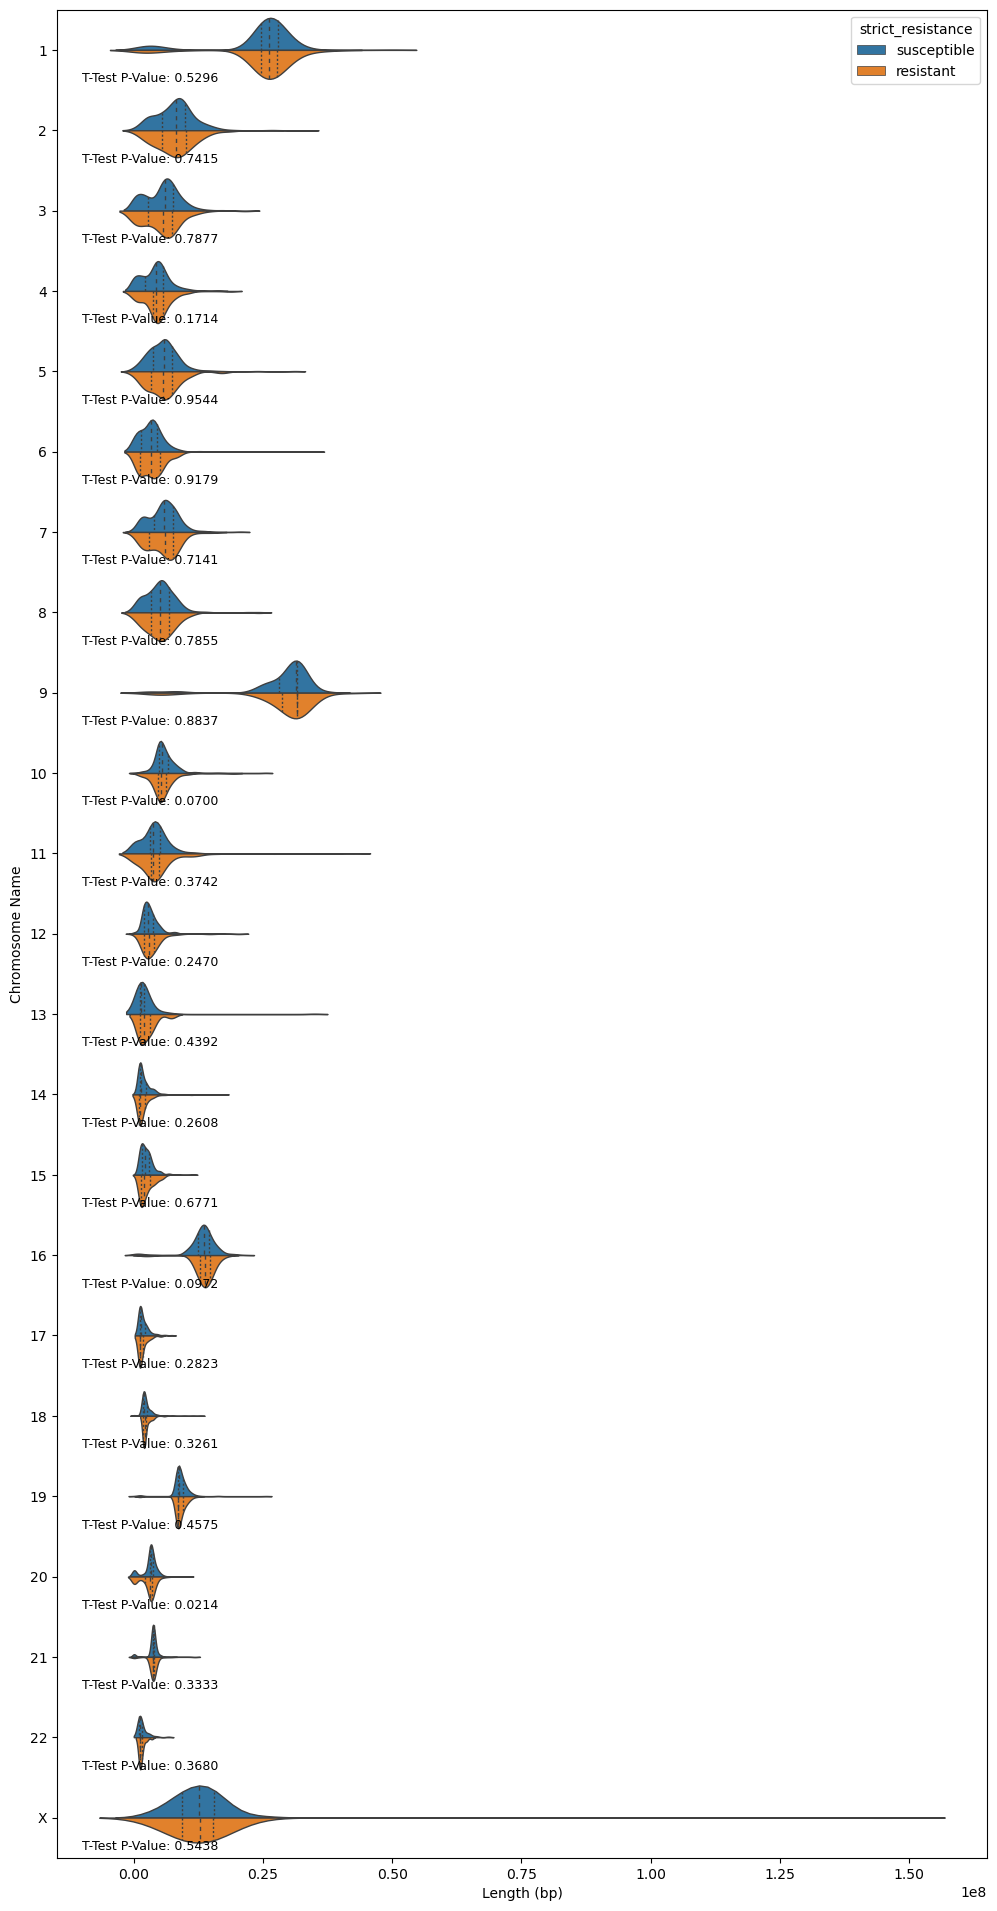

In [7]:
roh_total_length_resistance_association_results = {
    "Chromosome": [],
    "P-Value": [],
    "T-Statistic": [],
}

for chromosome, roh_total_lengths in roh_total_length_per_patient.groupby(
    "Chromosome Name"
):
    resistant_group = list(
        roh_total_lengths[roh_total_lengths["strict_resistance"] == "resistant"][
            "Length (bp)"
        ]
    )
    susceptible_group = list(
        roh_total_lengths[roh_total_lengths["strict_resistance"] != "resistant"][
            "Length (bp)"
        ]
    )
    tstat, pval = stats.ttest_ind(resistant_group, susceptible_group, equal_var=False)
    roh_total_length_resistance_association_results["Chromosome"].append(chromosome)
    roh_total_length_resistance_association_results["P-Value"].append(pval)
    roh_total_length_resistance_association_results["T-Statistic"].append(tstat)

    plt.figure(figsize=(9, 6))
    axs = sns.violinplot(
        x=roh_total_lengths["Length (bp)"],
        y=roh_total_lengths["strict_resistance"],
        width=0.45,
        inner="quartile",
    )
    axs.text(
        0.7, 0.9, f"T-Test P-Val: {pval:.4f}", fontsize=10, transform=axs.transAxes
    )
    sns.stripplot(
        x=roh_total_lengths["Length (bp)"],
        y=roh_total_lengths["strict_resistance"],
        color="k",
        alpha=0.5,
        jitter=True,
    )
    plt.savefig(
        f"Total ROH Length Association with Resistance/Chromosome {chromosome} T-Test.svg",
        format="svg",
    )
    plt.close()

roh_total_length_resistance_association_results = pd.DataFrame(
    roh_total_length_resistance_association_results
)
display(roh_total_length_resistance_association_results)

plt.figure(figsize=(12, 24))
ax = sns.violinplot(
    data=roh_total_length_per_patient,
    x="Length (bp)",
    y="Chromosome Name",
    hue="strict_resistance",
    order=chromosome_order,
    inner="quartile",
    split=True,
    linewidth=1,
)

for index, row in roh_total_length_resistance_association_results[
    ["Chromosome", "P-Value"]
].iterrows():
    chrom = row["Chromosome"]
    pval = row["P-Value"]
    ax.text(
        -0.1 * 10**8,
        chromosome_order.index(chrom) + 0.4,
        f"T-Test P-Value: {pval:.4f}",
        fontsize=9,
    )

plt.savefig(
    f"Total ROH Length Association with Resistance/Summary Chromosome T-Test.svg",
    format="svg",
)

### Cluster Highly Enriched ROHs

In [8]:
with pd.read_csv("Data/Binary ROHs.csv", chunksize=1) as chunked_binary_rohs:
    for chunk in chunked_binary_rohs:
        pure_chunk = chunk.iloc[:, 39:]
        print(pure_chunk)

   SNP_A-2153291  SNP_A-2266306  SNP_A-1944185  SNP_A-1967418  SNP_A-1999840  \
0              0              0              0              0              0   

   SNP_A-2258566  SNP_A-2082194  SNP_A-4248380  SNP_A-4249114  SNP_A-4273679  \
0              0              0              0              0              0   

   ...  SNP_A-1908961  SNP_A-1834587  SNP_A-4232981  SNP_A-1865423  \
0  ...              1              1              1              1   

   SNP_A-1926614  SNP_A-1957192  SNP_A-2069036  SNP_A-4267990  SNP_A-2267820  \
0              1              1              1              1              1   

   SNP_A-2283915  
0              1  

[1 rows x 440056 columns]
   SNP_A-2153291  SNP_A-2266306  SNP_A-1944185  SNP_A-1967418  SNP_A-1999840  \
1              0              0              0              0              0   

   SNP_A-2258566  SNP_A-2082194  SNP_A-4248380  SNP_A-4249114  SNP_A-4273679  \
1              0              0              0              0         

KeyboardInterrupt: 